# Aadhaar Enrolment and Update Activity — Data Analysis

Explore bundled monthly, state, district and age aggregate CSVs without downloading the large Excel exports. These are analysis summaries, not a cleaned row-level dataset. Biometric coverage is partial; counts represent activity, not unique residents.

Run cells in order locally or in Google Colab. Raw-data cleaning is a separate project and is not run here. Its repository link will be added when available.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

REPO = 'https://raw.githubusercontent.com/AishwaryB-SATI/UIDAI-Data-Analysis/main'
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
LOCAL_REPORTS = ROOT / 'reports'
REPORTS = LOCAL_REPORTS if (LOCAL_REPORTS / 'summary.json').exists() else REPO + '/reports'
def report_path(name):
    return str(REPORTS / name) if isinstance(REPORTS, Path) else REPORTS + '/' + name
SERVICES = ['enrolment', 'biometric', 'demographic']


## Recorded quality and coverage

The bundled summaries were generated in the earlier prepared project. This notebook loads them directly; it does not reread the source Excel sheets.

In [2]:
summary = pd.read_json(report_path('summary.json'))
summary[['service', 'rows', 'total_activity', 'exact_repeat_rows', 'excluded_rows', 'first_date', 'last_date']]


,service,rows,total_activity,exact_repeat_rows,excluded_rows,first_date,last_date
0,enrolment,1006029,5435702,22957,0,2025-03-02,2025-12-31
1,biometric,1361108,61776326,62846,0,2025-03-01,2025-12-29
2,demographic,2071700,49295187,473601,0,2025-03-01,2025-12-29


## Monthly activity and observed reporting days

A missing date is not established zero activity. Month-to-month peaks do not establish recurring seasonality.

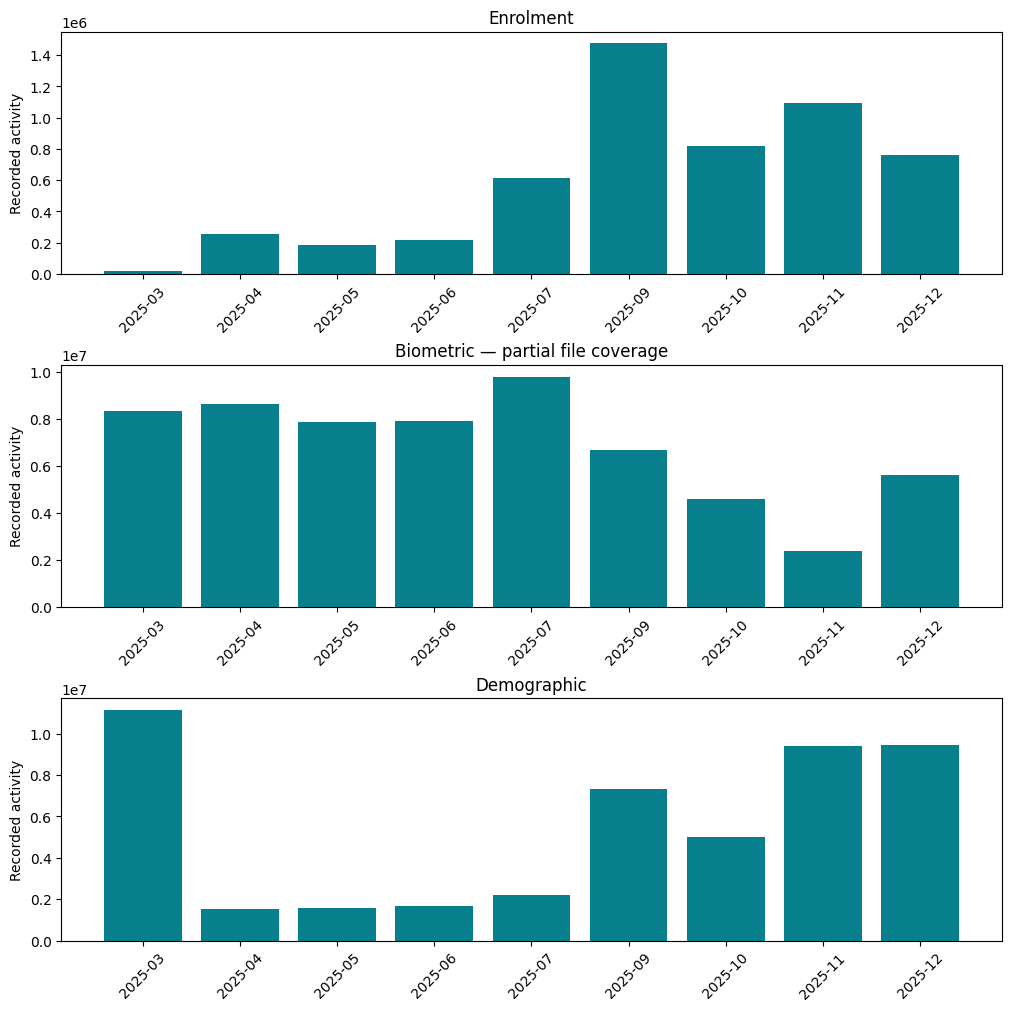

,period,activity,observed_days,rows
0,2025-03,16582,9,168
1,2025-04,257438,1,847
2,2025-05,183616,1,549
3,2025-06,215734,1,582
4,2025-07,616868,1,1184
5,2025-09,1475879,30,356059
6,2025-10,817920,18,211883
7,2025-11,1092007,20,272791
8,2025-12,759658,11,161966


In [3]:
monthly = {s: pd.read_csv(report_path(f'{s}_monthly.csv')) for s in SERVICES}
fig, axes = plt.subplots(3, 1, figsize=(10, 10), constrained_layout=True)
for ax, service in zip(axes, SERVICES):
    table = monthly[service]
    ax.bar(table['period'], table['activity'], color='#087f8c')
    ax.set_title(service.title() + (' — partial file coverage' if service == 'biometric' else ''))
    ax.set_ylabel('Recorded activity')
    ax.tick_params(axis='x', rotation=45)
plt.show()
monthly['enrolment']


## State labels and district totals

Labels preserve source aliases. Rankings are not population-normalized coverage rates. Districts are identified jointly with state.

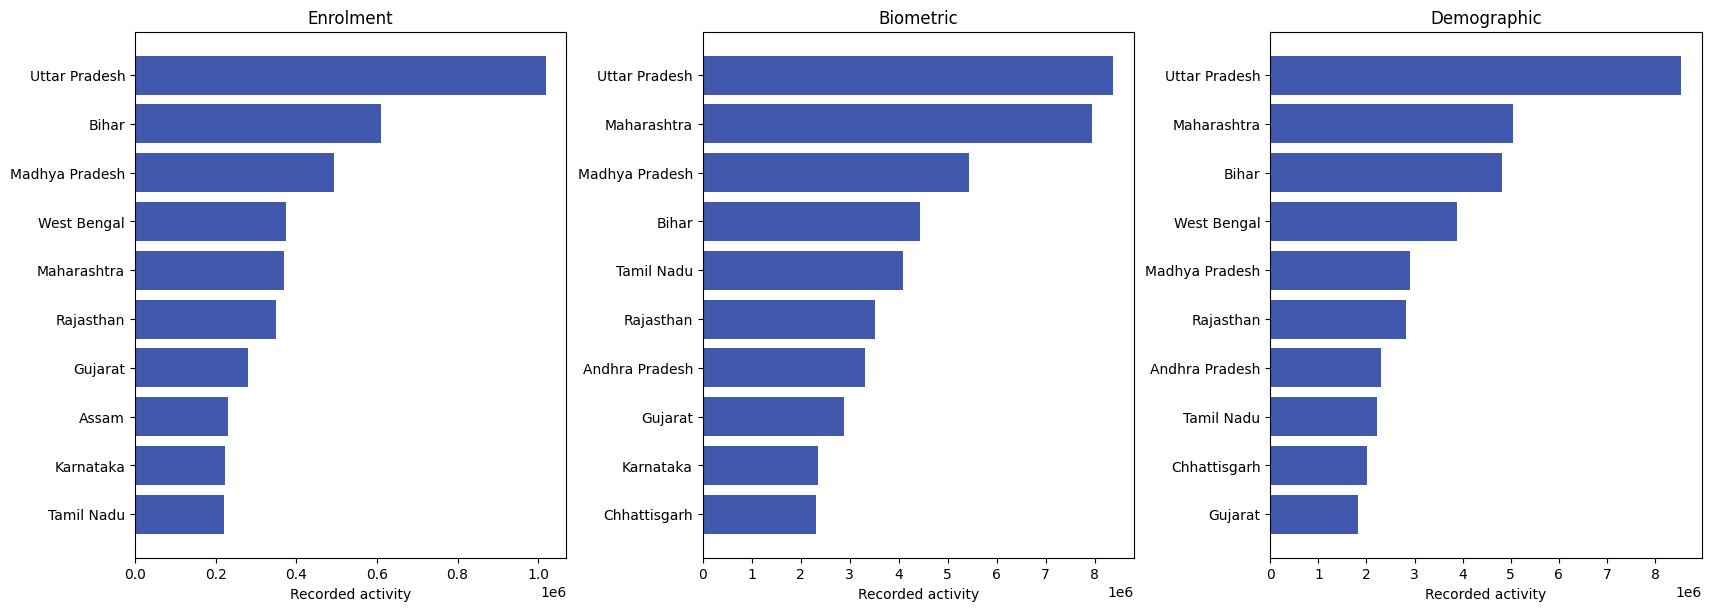

,state,district,activity
0,Maharashtra,Thane,43688
1,Bihar,Sitamarhi,42232
2,Uttar Pradesh,Bahraich,39338
3,West Bengal,Murshidabad,35911
4,West Bengal,South 24 Parganas,33540
5,Maharashtra,Pune,31763
6,Rajasthan,Jaipur,31146
7,Karnataka,Bengaluru,30980
8,Uttar Pradesh,Sitapur,30854
9,Bihar,West Champaran,30438


In [4]:
states = {s: pd.read_csv(report_path(f'{s}_states.csv')) for s in SERVICES}
districts = {s: pd.read_csv(report_path(f'{s}_districts.csv')) for s in SERVICES}
fig, axes = plt.subplots(1, 3, figsize=(17, 6), constrained_layout=True)
for ax, service in zip(axes, SERVICES):
    table = states[service].head(10).iloc[::-1]
    ax.barh(table['state'], table['activity'], color='#4059ad')
    ax.set_title(service.title())
    ax.set_xlabel('Recorded activity')
plt.show()
districts['enrolment'].head(10)


## Age bands

Source field names are retained. Confirm age-boundary definitions against source metadata before relabeling.

In [5]:
ages = {s: pd.read_csv(report_path(f'{s}_ages.csv')) for s in SERVICES}
for service, table in ages.items():
    print(service)
    print(table.to_string(index=False))


enrolment
    Unnamed: 0  activity
       age_0_5   3546965
      age_5_17   1720384
age_18_greater    168353
biometric
  Unnamed: 0  activity
bio_age_5_17  30115844
 bio_age_17_  31660482
demographic
   Unnamed: 0  activity
demo_age_5_17   4863424
 demo_age_17_  44431763


## Findings and limitations

See `reports/ANALYSIS.md` for the prepared findings. This is descriptive EDA; no predictive model or fraud detection is implemented. The bundled summaries preserve exact repeated source rows pending clarification of record identity. Original raw-file checks cannot be reconstructed from aggregate tables alone.
